# Notebook 11 – Dimensionality Reduction

# **Topic 1 – What is Dimensionality?**

## Step 1 – Understand the Concept

Dimensionality refers to the number of features or columns present in a dataset.

Each feature represents one type of information about an observation.

For example, a customer dataset may contain:
- Age
- Income
- Purchase Amount
- Shopping Frequency
- Customer Rating

This dataset has five dimensions because it contains five features.

In Machine Learning, dimensionality determines how much information is available for a model to learn patterns.

When a dataset contains many features, it is called high-dimensional data.

Dimensionality Reduction is a technique used to decrease the number of features while preserving as much useful information as possible.

PCA (Principal Component Analysis) is one of the commonly used dimensionality reduction techniques.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A student dataset contains:
- Study Hours
- Attendance
- Assignment Marks

There are three dimensions because the dataset has three features.

### 2. Real-World Example

An online shopping platform collects customer age, income, purchase history, browsing time, and product preferences.

Each collected attribute represents a dimension.

### 3. Business Example

A bank may maintain hundreds of customer-related features to understand customer behaviour and financial activities.

### 4. AI/ML Use Case

A Machine Learning model may use hundreds of features to predict customer churn.

Dimensionality reduction can transform these features into fewer components while retaining important patterns.

### Why is this useful?

- Reduces the number of input features.
- Can reduce computational requirements.
- Helps visualize complex datasets.
- Can reduce redundancy caused by correlated features.



In [1]:
# Import required libraries

import pandas as pd
import numpy as np

# Create a sample dataset

data = {
    "Age": [22, 25, 30, 35, 40],
    "Income": [20000, 25000, 30000, 35000, 40000],
    "Purchase_Amount": [1000, 1500, 2000, 2500, 3000],
    "Shopping_Hours": [2, 3, 4, 5, 6],
    "Customer_Rating": [3, 4, 3, 5, 4]
}

df = pd.DataFrame(data)

# Display dataset

display(df)

# Find dimensionality

number_of_features = df.shape[1]

print("Number of Dimensions:", number_of_features)


,Age,Income,Purchase_Amount,Shopping_Hours,Customer_Rating
0,22,20000,1000,2,3
1,25,25000,1500,3,4
2,30,30000,2000,4,3
3,35,35000,2500,5,5
4,40,40000,3000,6,4


Number of Dimensions: 5


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Imports Pandas and NumPy.
2. Creates a sample customer dataset.
3. Converts the dictionary into a DataFrame.
4. Uses shape[1] to count the number of columns.
5. Displays the total number of dimensions.

### Feature Analysis

- Feature Name: Age
- Source Column: Age
- Feature Logic: Original numerical value.
- Information Represented: Customer age.

The same interpretation applies to the other four original features.

### Why are these features used?

Each column provides different information about customer behaviour.

### How can they help Machine Learning?

A model can use these features to identify customer patterns and predict future purchasing behaviour.

### Dimensionality Before Reduction

## Step 4 – Justify Your Feature

### Feature Name
Original Customer Features

### Source Columns
Age, Income, Purchase_Amount, Shopping_Hours, Customer_Rating.

### Feature Logic / Formula
Each original column represents one dimension.

Dimensionality = Number of Input Features.

### Reason for Creation
These features provide different types of customer information.

### Expected Relationship with Target
Their relationship depends on the prediction target, such as Purchase Amount or Customer Churn.

### Potential Business Meaning
They describe customer demographics, spending behaviour, and satisfaction.

### Potential ML Value
They provide input information for Machine Learning models.

### Leakage Risk
No direct leakage is present in this sample dataset. However, target-derived information must not be included as an input feature.

### Final Decision
Retain the original features initially and evaluate whether dimensionality reduction is necessary.
    

# **Topic 2 – High-Dimensional Data**

## Step 1 – Understand the Concept

High-dimensional data refers to a dataset that contains a large number of features or columns.

For example, a dataset containing 1000 columns has 1000 dimensions.

High-dimensional datasets are commonly found in:
- Medical research
- Image processing
- Genomics
- Financial analysis
- Customer analytics

As the number of features increases, data analysis and Machine Learning can become more complex.

Some features may contain redundant or less useful information.

Dimensionality reduction helps represent high-dimensional data using fewer dimensions


## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset containing 3 student features is low-dimensional compared with a dataset containing 100 student-related features.

### 2. Real-World Example

An image with 100 × 100 pixels contains 10,000 pixel values.

Each pixel value can be treated as a feature.

### 3. Business Example

An e-commerce company may collect hundreds of customer features, including browsing activity, transaction history, product preferences, and engagement.

### 4. AI/ML Use Case

An image classification model may receive thousands of pixel features.

PCA can reduce these dimensions into a smaller number of principal components.

### Why is this useful?

It can simplify data representation, reduce processing requirements, and make visualization easier.

In [3]:
# Create a high-dimensional dataset

high_dimensional_data = pd.DataFrame(
    np.random.rand(100, 50),
    columns=[f"Feature_{i}" for i in range(1, 51)]
)

# Display dataset shape

print("Dataset Shape:", high_dimensional_data.shape)

print("Number of Records:", high_dimensional_data.shape[0])

print("Number of Dimensions:", high_dimensional_data.shape[1])

display(high_dimensional_data.head())

Dataset Shape: (100, 50)
Number of Records: 100
Number of Dimensions: 50


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,...,Feature_41,Feature_42,Feature_43,Feature_44,Feature_45,Feature_46,Feature_47,Feature_48,Feature_49,Feature_50
0,0.287813,0.202299,0.123890,0.788153,0.399763,0.646723,0.808709,0.955874,0.646809,0.427852,...,0.635401,0.486790,0.517378,0.438790,0.496612,0.622947,0.985144,0.718039,0.235241,0.129412
1,0.487079,0.314467,0.659780,0.573195,0.665130,0.919023,0.037164,0.585208,0.609343,0.322590,...,0.608287,0.200793,0.880906,0.214609,0.922257,0.379961,0.699986,0.984401,0.957739,0.240536
2,0.168215,0.929427,0.937736,0.408584,0.147239,0.515358,0.963501,0.492149,0.711282,0.599612,...,0.678955,0.432884,0.147036,0.400057,0.260355,0.332706,0.310030,0.558547,0.179083,0.052660
3,0.561443,0.490786,0.138099,0.895129,0.288996,0.470828,0.379000,0.949093,0.868864,0.857359,...,0.465695,0.640669,0.758904,0.515213,0.274966,0.443382,0.988780,0.247745,0.403707,0.412152
4,0.035632,0.917256,0.205591,0.933421,0.397905,0.619549,0.298100,0.214113,0.614469,0.642312,...,0.462949,0.542532,0.977765,0.820884,0.911626,0.181203,0.532778,0.544827,0.398264,0.864019


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Generates 100 observations.
2. Creates 50 numerical features.
3. Stores the values in a Pandas DataFrame.
4. Displays the dataset shape.
5. Identifies the number of dimensions.

### Why were these features created?

The 50 columns represent different input measurements.

### Source Columns
Feature_1 to Feature_50.

### Information Represented
Each column represents one numerical measurement.

### ML Usefulness
A model can use these features to identify patterns, although the usefulness of each feature must be evaluated.

### Before Reduction
50 dimensions.

### After Reduction
The dataset can potentially be represented using fewer principal components.

## Step 4 – Justify Your Feature

### Feature Name
High-Dimensional Input Features

### Source Columns
Feature_1 to Feature_50.

### Feature Logic / Formula
Each feature represents an independent input column.

### Reason for Creation
To demonstrate a dataset with many dimensions.

### Expected Relationship with Target
Unknown until a target variable and feature analysis are available.

### Potential Business Meaning
The columns represent different measurements collected from a business process.

### Potential ML Value
Multiple features may provide useful information for model training.

### Leakage Risk
No target leakage is introduced because this is a randomly generated dataset without a target variable.

### Final Decision
Evaluate the features before retaining or reducing them. Do not assume every feature is useful.

# **Topic 3 – Curse of Dimensionality**

## Step 1 – Understand the Concept

The Curse of Dimensionality refers to the problems that can occur when the number of features in a dataset becomes very large.

As dimensions increase, the feature space grows rapidly.

This creates several challenges:

1. Data becomes sparse.
2. More observations may be required.
3. Distance measurements can become less meaningful.
4. Model complexity may increase.
5. Computational requirements may increase.

For example, understanding customer behaviour using 5 features may be easier than using 500 unnecessary or highly redundant features.

Dimensionality reduction can help address some of these challenges.

However, PCA does not automatically solve every problem associated with high-dimensional data.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset with 2 features can be visualized using a two-dimensional graph.

A dataset with 100 features cannot be directly visualized using an ordinary two-dimensional graph.

### 2. Real-World Example

Medical datasets may contain thousands of gene measurements but only a limited number of patient observations.

This creates a high-dimensional learning problem.

### 3. Business Example

A company may collect many customer attributes but have relatively few customers available for model training.

### 4. AI/ML Use Case

A K-Nearest Neighbors model uses distances between observations.

In high-dimensional spaces, distance differences can become less informative.

### Why is this useful?

Understanding this problem helps engineers decide whether dimensionality reduction or feature selection may improve the learning process.

In [5]:
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate high-dimensional classification data

X, y = make_classification(
    n_samples=500,
    n_features=100,
    n_informative=10,
    n_redundant=20,
    n_repeated=0,
    random_state=42
)

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train KNN model

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

# Make predictions

predictions = knn.predict(X_test)

print("Number of Features:", X.shape[1])

print("Accuracy:", accuracy_score(y_test, predictions))

Number of Features: 100
Accuracy: 0.9


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Creates a classification dataset with 100 features.
2. Includes informative and redundant features.
3. Splits the data into training and testing sets.
4. Trains a KNN classifier.
5. Evaluates its predictions using accuracy.

### Source Columns
100 generated numerical features.

### Why were these features created?

To simulate a high-dimensional dataset containing useful and redundant information.

### Information Represented
The features represent numerical measurements used for classification.

### How can they help ML?

Informative features help the model distinguish between classes.

Redundant features may add unnecessary complexity.

### Important Observation

Accuracy alone does not prove that the Curse of Dimensionality has occurred.

A proper experiment should compare models across different dimensions using the same evaluation procedure.

## Step 4 – Justify Your Feature

### Feature Name
High-Dimensional Numerical Features

### Source Columns
100 generated features.

### Feature Logic / Formula
Generated using make_classification().

### Reason for Creation
To demonstrate how a model works with many input dimensions.

### Expected Relationship with Target
10 informative features are designed to contribute to the classification target. Other features may be redundant or uninformative.

### Potential Business Meaning
Represents multiple measurements collected from a business process.

### Potential ML Value
Useful features can improve classification, while unnecessary features may increase complexity.

### Leakage Risk
The generated features do not directly include the target as an input. Data splitting is performed before model training.

### Final Decision
Retain informative features and evaluate redundant or irrelevant features before final model training.

# **Topic 4 – Why Reduce Dimensions?**

## Step 1 – Understand the Concept

Dimensionality reduction decreases the number of input dimensions in a dataset.

It is useful when a dataset contains many features, especially when some features are correlated or contain overlapping information.

Main reasons for reducing dimensions:

1. Reduce computational requirements.
2. Simplify data representation.
3. Reduce redundant information.
4. Improve visualization.
5. Potentially reduce overfitting.
6. Make high-dimensional datasets easier to analyze.

Dimensionality reduction can be performed using PCA.

PCA transforms the original features into a smaller set of new features called principal components.

Important: Reducing dimensions does not guarantee better model performance. The results must be evaluated.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset contains 20 features.

PCA can transform these features into 2 principal components.

### 2. Real-World Example

An image dataset may contain thousands of pixel features.

Dimensionality reduction can represent the images using fewer numerical components.

### 3. Business Example

A bank collects multiple financial indicators that may contain similar information.

PCA can combine correlated indicators into fewer components.

### 4. AI/ML Use Case

A classification model can use principal components instead of all original features.

### Why is this useful?

It may reduce processing time, simplify visualization, and help remove redundant information.

In [6]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset

wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Standardize the features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Apply PCA

pca = PCA(n_components=2)

X_reduced = pca.fit_transform(X_scaled)

# Display dimensionality comparison

print("Original Shape:", X.shape)

print("Reduced Shape:", X_reduced.shape)

print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

Original Shape: (178, 13)
Reduced Shape: (178, 2)
Explained Variance Ratio: [0.36198848 0.1920749 ]


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Loads the Wine dataset from Scikit-learn.
2. Selects 13 original numerical features.
3. Standardizes the features.
4. Applies PCA with 2 components.
5. Transforms the original dataset into 2 dimensions.

### Source Columns

The 13 original Wine dataset features.

### Feature Logic

PCA creates two new features by combining weighted contributions from the original features.

### Information Represented

PC1 and PC2 represent directions of maximum variance in the standardized dataset.

### Before Reduction
13 dimensions.

### After Reduction
2 dimensions.

### ML Usefulness

The two components can be used as inputs for a Machine Learning model.

The amount of retained information should be checked using explained variance.

## Step 4 – Justify Your Feature

### Feature Name
PC1 and PC2

### Source Columns
All 13 original Wine dataset features.

### Feature Logic / Formula
Each principal component is a weighted linear combination of standardized input features.

PC1 = w1X1 + w2X2 + ... + w13X13

PC2 = v1X1 + v2X2 + ... + v13X13

### Reason for Creation
To reduce 13 dimensions into 2 components.

### Expected Relationship with Target
PCA is unsupervised and does not use the target while creating components. The relationship with wine class must be evaluated separately.

### Potential Business Meaning
The components summarize patterns across multiple wine measurements.

### Potential ML Value
They can reduce input dimensions and provide compact model inputs.

### Leakage Risk
PCA must be fitted only on training data in predictive workflows.

### Final Decision
Retain PC1 and PC2 if they preserve sufficient useful information and provide acceptable model performance.

# **Topic 5 – PCA (Principal Component Analysis)**

## Step 1 – Understand the Concept

Principal Component Analysis is an unsupervised dimensionality reduction technique.

It transforms a dataset containing multiple numerical features into a smaller number of new features called principal components.

PCA identifies directions in the data where variance is highest.

The first principal component captures the maximum possible variance.

The second principal component captures the maximum remaining variance while being perpendicular to the first component.

The same process continues for additional components.

PCA generally requires numerical features and is sensitive to differences in feature scales.

Therefore, standardization is commonly performed before applying PCA.

PCA does not select original columns. It creates new transformed components.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

Suppose a dataset contains:
- Height
- Weight
- Waist Measurement

These features may contain overlapping information.

PCA can combine them into fewer components.

### 2. Real-World Example

In image processing, PCA can reduce the number of pixel dimensions while retaining major patterns.

### 3. Business Example

A bank may use several correlated financial indicators to create a smaller number of components representing financial behaviour.

### 4. AI/ML Use Case

PCA can transform high-dimensional input data before classification or clustering.

### Why is this useful?

It can reduce the number of input dimensions and help identify important patterns in numerical data.

In [7]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load data

wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Standardization

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Apply PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Convert components into DataFrame

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

display(pca_df.head())

print("Original Features:", X.shape[1])

print("Principal Components:", pca.n_components_)

,PC1,PC2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


Original Features: 13
Principal Components: 2


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Loads the Wine dataset.
2. Extracts 13 numerical features.
3. Standardizes the data using StandardScaler.
4. Creates a PCA object with 2 components.
5. Fits PCA and transforms the data.
6. Stores the transformed values in a DataFrame.

### Why were the features created?

PC1 and PC2 summarize information from the original 13 features.

### Source Columns
All 13 original Wine features.

### Feature Information
Each component represents a weighted combination of original measurements.

### ML Usefulness
The components can be used as compact input features for classification and clustering.

### Before Reduction
13 dimensions.

### After Reduction
2 dimensions.

## Step 4 – Justify Your Feature

### Feature Name
PC1 and PC2

### Source Columns
13 original Wine features.

### Feature Logic / Formula
Weighted linear combinations of standardized input features.

### Reason for Creation
To reduce the number of dimensions while preserving as much variance as possible.

### Expected Relationship with Target
PCA does not use the target. Component-target relationships must be checked after transformation.

### Potential Business Meaning
Summarized patterns across wine characteristics.

### Potential ML Value
Provides fewer input dimensions for Machine Learning.

### Leakage Risk
Fitting PCA on the entire dataset before train-test splitting can cause data leakage.

### Final Decision
Retain components based on explained variance and downstream model performance.

# **Topic 6 – Principal Components**

## Step 1 – Understand the Concept

Principal Components are new features created by PCA from the original numerical features.

They are combinations of the original features.

Principal components are arranged according to the amount of variance they explain.

### PC1 – First Principal Component

Captures the maximum possible variance in the dataset.

### PC2 – Second Principal Component

Captures the maximum remaining variance and is orthogonal to PC1.

### PC3 – Third Principal Component

Captures the maximum remaining variance after PC1 and PC2.

Each principal component is mathematically independent in terms of linear correlation with the other components in the PCA training data.

Principal components are not the same as the original columns.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

Height and Weight may be combined into a principal component representing a direction of shared variation.

### 2. Real-World Example

Image pixel values can be transformed into principal components that summarize major image patterns.

### 3. Business Example

Customer spending, transaction count, and purchase frequency may contribute to components summarizing customer activity.

### 4. AI/ML Use Case

A classification algorithm can use PC1, PC2, and PC3 instead of dozens of original features.

### Why is this useful?

Principal components provide a smaller representation of the original feature space.

In [8]:
# Create PCA with 5 components

pca_components = PCA(n_components=5)

components = pca_components.fit_transform(X_scaled)

# Store components

components_df = pd.DataFrame(
    components,
    columns=[
        "PC1", "PC2", "PC3", "PC4", "PC5"
    ]
)

display(components_df.head())

print("Number of Components:",
      components_df.shape[1])

,PC1,PC2,PC3,PC4,PC5
0,3.316751,1.443463,-0.165739,-0.215631,0.693043
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655
2,2.516740,1.031151,0.982819,0.724902,-0.251033
3,3.757066,2.756372,-0.176192,0.567983,-0.311842
4,1.008908,0.869831,2.026688,-0.409766,0.298458


Number of Components: 5


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Creates a PCA model with 5 components.
2. Fits the model using standardized input features.
3. Transforms the original data.
4. Creates five new component columns.
5. Displays the transformed dataset.

### Source Columns
All 13 standardized Wine features.

### Feature Logic
Each PC is a weighted combination of the original columns.

### Information Represented
Each PC captures a different direction of variation.

### ML Usefulness
The components can replace original inputs in a downstream model.

### Before Reduction
13 features.

### After Reduction
5 components.

## Step 4 – Justify Your Feature

### Feature Name
PC1, PC2, PC3, PC4, PC5

### Source Columns
All 13 Wine features.

### Feature Logic / Formula
Each component is calculated using PCA loadings multiplied by standardized feature values.

### Reason for Creation
To represent the original dataset using five dimensions.

### Expected Relationship with Target
The relationship is not guaranteed because PCA does not use target information.

### Potential Business Meaning
Each component summarizes a pattern across multiple wine measurements.

### Potential ML Value
Reduces input dimensions and may simplify model training.

### Leakage Risk
PCA must be fitted on training data only when building predictive models.

### Final Decision
Retain only components that provide sufficient information for the intended task.

# **Topic 7 – Explained Variance**

## Step 1 – Understand the Concept

Explained Variance measures how much of the total variance in the original dataset is captured by a principal component.

PCA provides an explained_variance_ratio_ attribute.

This value represents the proportion of total variance explained by each component.

For example:

- PC1 explains 50%.
- PC2 explains 25%.
- PC3 explains 15%.

The cumulative explained variance of the first two components is 75%.

Cumulative explained variance helps determine how many components should be retained.

A higher explained variance indicates that more of the original dataset's variation is represented.

However, high explained variance does not always mean better prediction performance.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

If PC1 explains 60% of the variance and PC2 explains 25%, both together explain 85%.

### 2. Real-World Example

In image compression, explained variance helps measure how much image variation is retained after dimensionality reduction.

### 3. Business Example

A bank can evaluate how much information is represented by a smaller set of components created from financial indicators.

### 4. AI/ML Use Case

An ML engineer may select enough components to retain 90% or 95% of the total variance.

### Why is this useful?

It helps select the number of principal components instead of choosing an arbitrary number.

In [9]:
# Apply PCA without specifying component count

pca_variance = PCA()

pca_variance.fit(X_scaled)

# Individual explained variance

individual_variance = (
    pca_variance.explained_variance_ratio_
)

# Cumulative explained variance

cumulative_variance = np.cumsum(
    individual_variance
)

variance_df = pd.DataFrame({
    "Component": [
        f"PC{i}" for i in range(1, len(individual_variance) + 1)
    ],
    "Explained_Variance": individual_variance,
    "Cumulative_Variance": cumulative_variance
})

display(variance_df)

print("Total Explained Variance:",
      cumulative_variance[-1])

,Component,Explained_Variance,Cumulative_Variance
0,PC1,0.361988,0.361988
1,PC2,0.192075,0.554063
2,PC3,0.111236,0.665300
3,PC4,0.070690,0.735990
4,PC5,0.065633,0.801623
5,PC6,0.049358,0.850981
6,PC7,0.042387,0.893368
7,PC8,0.026807,0.920175
8,PC9,0.022222,0.942397
9,PC10,0.019300,0.961697


Total Explained Variance: 1.0


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Fits PCA using all standardized features.
2. Extracts individual explained variance ratios.
3. Calculates cumulative explained variance.
4. Creates a summary DataFrame.
5. Displays the information captured by each component.

### Source Columns
All 13 standardized Wine features.

### Feature Logic
Explained Variance Ratio = Variance Explained by a Component / Total Variance.

### Why is this calculated?

To understand how much information each component captures.

### ML Usefulness
Helps select an appropriate number of components for downstream models.

### Important Observation
The sum of explained variance ratios across all components is approximately 1.

## Step 4 – Justify Your Feature

### Feature Name
Principal Components selected using Explained Variance.

### Source Columns
All 13 Wine features.

### Feature Logic / Formula
Cumulative Explained Variance = Sum of individual explained variance ratios.

### Reason for Creation
To identify how many components are needed to preserve a desired amount of variance.

### Expected Relationship with Target
Explained variance measures variation in input data, not direct target relevance.

### Potential Business Meaning
Shows how much variation in business measurements is summarized by each component.

### Potential ML Value
Supports component selection and dimensionality reduction decisions.

### Leakage Risk
Variance analysis performed on the complete dataset before splitting can expose information about the test distribution.

### Final Decision
Retain components based on cumulative variance and validate their usefulness using training-only model selection.

# **Topic 8 – Eigenvectors**

## Step 1 – Understand the Concept

Eigenvectors are mathematical vectors that represent important directions in a transformation.

In PCA, eigenvectors of the covariance matrix identify the directions along which the data varies.

These directions are used to create principal components.

Each eigenvector contains weights or coefficients corresponding to the original features.

These weights are also called PCA loadings.

An eigenvector associated with the largest eigenvalue represents the direction of maximum variance.

Eigenvectors determine the orientation of the principal components.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

If Height and Weight change together, an eigenvector may identify a direction that represents their shared variation.

### 2. Real-World Example

Image processing uses eigenvectors to identify major patterns across pixel measurements.

### 3. Business Example

A financial dataset may contain correlated measurements. Eigenvectors identify directions that summarize their combined variation.

### 4. AI/ML Use Case

PCA uses eigenvectors to transform original features into principal components.

### Why is this useful?

Eigenvectors provide the mathematical directions required to transform high-dimensional data.

In [10]:
# Fit PCA

pca_eigen = PCA(n_components=3)

pca_eigen.fit(X_scaled)

# Extract eigenvectors / principal axes

eigenvectors = pca_eigen.components_

eigenvector_df = pd.DataFrame(
    eigenvectors,
    columns=X.columns,
    index=["PC1", "PC2", "PC3"]
)

display(eigenvector_df)

print("Eigenvector Matrix Shape:",
      eigenvectors.shape)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
PC1,0.144329,-0.245188,-0.002051,-0.239320,0.141992,0.394661,0.422934,-0.298533,0.313429,-0.088617,0.296715,0.376167,0.286752
PC2,0.483652,0.224931,0.316069,-0.010591,0.299634,0.065040,-0.003360,0.028779,0.039302,0.529996,-0.279235,-0.164496,0.364903
PC3,-0.207383,0.089013,0.626224,0.612080,0.130757,0.146179,0.150682,0.170368,0.149454,-0.137306,0.085222,0.166005,-0.126746


Eigenvector Matrix Shape: (3, 13)


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Fits PCA using standardized Wine features.
2. Extracts the principal axes.
3. Stores the eigenvector coefficients.
4. Displays the contribution weights of original features.

### Source Columns
13 standardized Wine features.

### Feature Logic
Each eigenvector contains coefficients representing the direction of a principal component.

### Information Represented
The values show how the original features contribute to each component.

### ML Usefulness
These directions are used to transform original data into principal components.

### Important Note
The sign of an eigenvector can be reversed without changing the mathematical meaning of its principal direction.

## Step 4 – Justify Your Feature

### Feature Name
PCA Eigenvectors / Component Loadings

### Source Columns
All 13 standardized Wine features.

### Feature Logic / Formula
Eigenvectors are obtained from the covariance matrix decomposition.

### Reason for Creation
To identify the directions used for dimensionality reduction.

### Expected Relationship with Target
Eigenvectors are calculated without using the target variable.

### Potential Business Meaning
Their coefficients indicate how different measurements contribute to a summarized pattern.

### Potential ML Value
They define the transformation from original features into principal components.

### Leakage Risk
Eigenvectors learned from the complete dataset can cause train-test information leakage.

### Final Decision
Retain the fitted PCA transformation for the selected training workflow; do not treat eigenvector coefficients as ordinary observations.

# **Topic 9 – Eigenvalues**

## Step 1 – Understand the Concept

Eigenvalues measure the amount of variance associated with each eigenvector in PCA.

Each eigenvalue represents the variance captured along a particular principal direction.

A larger eigenvalue means that the corresponding principal component captures more variance.

PCA sorts components in descending order of eigenvalues.

Therefore:
- PC1 has the largest eigenvalue.
- PC2 has the second-largest eigenvalue.
- PC3 has the third-largest eigenvalue.

Eigenvalues help identify which components contain more variation in the dataset.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

Suppose three components have eigenvalues:
- PC1 = 5
- PC2 = 2
- PC3 = 1

PC1 captures the largest amount of variance.

### 2. Real-World Example

In image compression, components with larger eigenvalues represent directions containing more image variation.

### 3. Business Example

A company may identify which components explain more variation across customer measurements.

### 4. AI/ML Use Case

Eigenvalues help determine how many principal components should be retained.

### Why is this useful?

They help distinguish high-variance components from components containing relatively little variance.

In [11]:
# Fit PCA

pca_values = PCA()

pca_values.fit(X_scaled)

# Extract eigenvalues

eigenvalues = pca_values.explained_variance_

eigenvalue_df = pd.DataFrame({
    "Component": [
        f"PC{i}" for i in range(1, len(eigenvalues) + 1)
    ],
    "Eigenvalue": eigenvalues
})

display(eigenvalue_df)

print("Largest Eigenvalue:", eigenvalues[0])

,Component,Eigenvalue
0,PC1,4.732437
1,PC2,2.511081
2,PC3,1.454242
3,PC4,0.924166
4,PC5,0.858049
5,PC6,0.645282
6,PC7,0.554141
7,PC8,0.350466
8,PC9,0.290512
9,PC10,0.252320


Largest Eigenvalue: 4.732436977583587


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Fits PCA using all standardized features.
2. Extracts eigenvalues through explained_variance_.
3. Creates a DataFrame.
4. Displays eigenvalues in component order.

### Source Columns
All 13 standardized Wine features.

### Feature Logic
Each eigenvalue represents the variance captured by its corresponding principal component.

### Information Represented
The values indicate how much variation exists along each principal direction.

### ML Usefulness
Helps determine which components are important for representing the dataset.

## Step 4 – Justify Your Feature

### Feature Name
PCA Eigenvalues

### Source Columns
All 13 standardized Wine features.

### Feature Logic / Formula
Eigenvalues are obtained through covariance matrix eigenvalue decomposition.

### Reason for Creation
To measure the variance captured by each principal component.

### Expected Relationship with Target
Eigenvalues do not measure target relevance.

### Potential Business Meaning
They show how much variation exists in summarized business measurements.

### Potential ML Value
They support component ranking and dimensionality decisions.

### Leakage Risk
Calculating eigenvalues using the entire dataset before train-test separation can expose test-distribution information.

### Final Decision
Retain the eigenvalue information for component evaluation, not as ordinary model input features.

# **Topic 10 – PCA Transformation**

## Step 1 – Understand the Concept

PCA Transformation is the process of converting original features into principal components.

The transformation involves:

1. Standardizing the input features.
2. Calculating the principal directions.
3. Selecting the required number of components.
4. Projecting the original observations onto those directions.

The transformed dataset contains new columns such as PC1, PC2, and PC3.

The original feature values are represented using combinations of the selected principal directions.

The number of dimensions decreases when fewer components are selected.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset with 10 features can be transformed into 3 principal components.

### 2. Real-World Example

A face recognition system can transform pixel measurements into a smaller representation.

### 3. Business Example

A bank can transform several correlated financial indicators into fewer principal components.

### 4. AI/ML Use Case

The transformed dataset can be supplied to a classification algorithm.

### Why is this useful?

It creates a compact representation of the original numerical features.

In [12]:
from sklearn.model_selection import train_test_split

# Separate features and target

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target

# Split before fitting preprocessing steps

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize using training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Apply PCA

pca_transform = PCA(n_components=2)

X_train_pca = pca_transform.fit_transform(
    X_train_scaled
)

X_test_pca = pca_transform.transform(
    X_test_scaled
)

print("Original Training Shape:", X_train.shape)

print("Transformed Training Shape:", X_train_pca.shape)

print("Original Testing Shape:", X_test.shape)

print("Transformed Testing Shape:", X_test_pca.shape)

Original Training Shape: (142, 13)
Transformed Training Shape: (142, 2)
Original Testing Shape: (36, 13)
Transformed Testing Shape: (36, 2)


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Separates input features and target.
2. Splits data into training and testing sets.
3. Fits StandardScaler only on training data.
4. Transforms both datasets using the same scaler.
5. Fits PCA only on training data.
6. Transforms training and testing features.

### Source Columns
All 13 Wine dataset features.

### Feature Logic
Each principal component is a weighted sum of standardized original features.

### Information Represented
PC1 and PC2 represent the first two principal directions.

### ML Usefulness
The transformed features can be used for model training without fitting PCA on test data.

### Leakage Prevention
The scaler and PCA are fitted only on training data.

## Step 4 – Justify Your Feature

### Feature Name
PC1 and PC2

### Source Columns
All 13 Wine numerical features.

### Feature Logic / Formula
PCA projection of standardized input features onto the first two principal directions.

### Reason for Creation
To transform 13 original dimensions into 2 dimensions.

### Expected Relationship with Target
The relationship with wine class must be evaluated after transformation.

### Potential Business Meaning
They summarize patterns across multiple wine measurements.

### Potential ML Value
They provide fewer numerical inputs for downstream classification.

### Leakage Risk
PCA fitting on test data would cause data leakage. The implementation avoids this.

### Final Decision
Retain the components if they preserve enough useful information and support acceptable predictive performance.

# **Topic 11 – PCA Visualization**

## Step 1 – Understand the Concept

PCA Visualization is the process of displaying high-dimensional data using a smaller number of principal components.

A common approach is to use:
- PC1 on the X-axis.
- PC2 on the Y-axis.

This creates a two-dimensional scatter plot.

Different colours can represent different classes.

PCA visualization helps identify:
- Clusters
- Separation between classes
- Overlapping observations
- Patterns in the dataset

Visualization provides an understanding of the data but does not guarantee that the classes will be perfectly separated.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

Student performance data with five features can be reduced to PC1 and PC2 and displayed using a scatter plot.

### 2. Real-World Example

Image datasets can be visualized using two principal components to understand major patterns.

### 3. Business Example

A company can visualize customers using purchasing and engagement measurements to understand customer groups.

### 4. AI/ML Use Case

PCA visualization can help an ML engineer explore whether observations from different classes show visible patterns.

### Why is this useful?

It makes complex datasets easier to explore and understand visually.

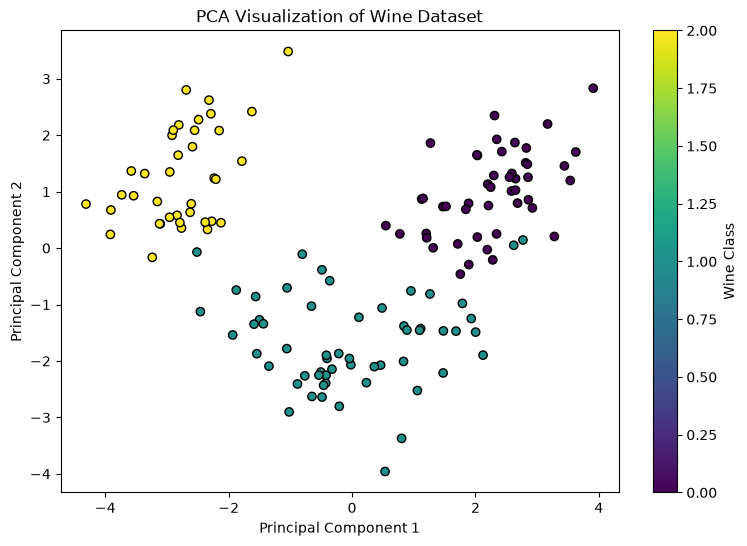

In [13]:
import matplotlib.pyplot as plt

# Use transformed training data from Topic 10

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    edgecolor="black"
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization of Wine Dataset")

plt.colorbar(scatter, label="Wine Class")

plt.show()

## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Uses the PCA-transformed training dataset.
2. Selects PC1 and PC2.
3. Creates a scatter plot.
4. Colours the observations based on their wine class.
5. Displays the distribution of observations.

### Source Columns
The 13 original Wine features, transformed into PC1 and PC2.

### Feature Logic
The X-axis represents PC1 and the Y-axis represents PC2.

### Information Represented
The graph displays how observations are distributed in the reduced feature space.

### ML Usefulness
Helps understand patterns and possible class separation.

### Important Note
The target is used only for colouring the visualization, not for fitting PCA.

## Step 4 – Justify Your Feature

### Feature Name
PC1 and PC2 Visualization

### Source Columns
All 13 Wine features.

### Feature Logic / Formula
PCA transformation followed by a two-dimensional scatter plot.

### Reason for Creation
To visualize high-dimensional observations in two dimensions.

### Expected Relationship with Target
Class separation may be visible, but PCA does not optimize components using the target.

### Potential Business Meaning
Shows patterns among observations based on multiple measurements.

### Potential ML Value
Supports exploratory analysis and component interpretation.

### Leakage Risk
PCA must be fitted on training data. Target labels must not be used to fit PCA in this unsupervised workflow.

### Final Decision
Retain PC1 and PC2 for visualization. Their usefulness as model features requires separate evaluation.

# **Topic 12 – Advantages of PCA**

## Step 1 – Understand the Concept

PCA provides several advantages when working with high-dimensional numerical datasets.

### Main Advantages

1. Dimensionality Reduction
   Reduces the number of input features.

2. Computational Efficiency
   Fewer dimensions may reduce processing requirements.

3. Removes Linear Correlation
   Principal components are uncorrelated in the training data.

4. Data Visualization
   High-dimensional data can be represented in two or three dimensions.

5. Noise Reduction
   Removing low-variance components may reduce some noise.

6. Simplifies Data Representation
   Multiple original features can be summarized using fewer components.

PCA is useful when the original features contain overlapping information.

However, PCA does not guarantee improved accuracy or complete noise removal.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset with 10 correlated features can be represented using 3 principal components.

### 2. Real-World Example

Image processing applications can reduce thousands of pixel dimensions into fewer components.

### 3. Business Example

A bank can summarize several correlated financial measurements into fewer components.

### 4. AI/ML Use Case

A classification model can use PCA-transformed features instead of all original features.

### Why is this useful?

- Reduces dimensionality.
- Simplifies data visualization.
- Can reduce redundancy.
- May improve computational efficiency.

In [14]:
# Fit PCA using training data

pca_advantage = PCA(n_components=5)

X_train_reduced = pca_advantage.fit_transform(
    X_train_scaled
)

# Check dimensions

print("Original Dimensions:", X_train_scaled.shape[1])

print("Reduced Dimensions:", X_train_reduced.shape[1])

# Check explained variance

print(
    "Individual Explained Variance:",
    pca_advantage.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    pca_advantage.explained_variance_ratio_.sum()
)

# Check correlation between principal components

pca_advantage_df = pd.DataFrame(
    X_train_reduced,
    columns=[f"PC{i}" for i in range(1, 6)]
)

display(pca_advantage_df.corr())

Original Dimensions: 13
Reduced Dimensions: 5
Individual Explained Variance: [0.35792104 0.19270671 0.11019835 0.07272276 0.06721919]
Total Explained Variance: 0.8007680555289934


,PC1,PC2,PC3,PC4,PC5
PC1,1.000000e+00,3.870109e-16,7.510158e-17,8.201106e-18,-1.225252e-16
PC2,3.870109e-16,1.000000e+00,1.203043e-16,-3.637542e-16,1.934036e-16
PC3,7.510158e-17,1.203043e-16,1.000000e+00,1.192488e-16,2.704303e-16
PC4,8.201106e-18,-3.637542e-16,1.192488e-16,1.000000e+00,-4.894507e-16
PC5,-1.225252e-16,1.934036e-16,2.704303e-16,-4.894507e-16,1.000000e+00


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Fits PCA using five components.
2. Transforms the training dataset.
3. Compares original and reduced dimensions.
4. Calculates explained variance.
5. Checks the correlation between principal components.

### Why were the features created?

The five components summarize information from the original 13 features.

### Source Columns
All 13 standardized Wine features.

### Feature Logic
Each component is a weighted combination of the original columns.

### Information Represented
The components capture different directions of variation.

### ML Usefulness
They can reduce the number of model inputs and remove linear correlation between transformed components.

### Important Observation
The component correlation matrix should be approximately an identity matrix, allowing for numerical precision.

    

## Step 4 – Justify Your Feature

### Feature Name
PC1, PC2, PC3, PC4, PC5

### Source Columns
All 13 Wine dataset features.

### Feature Logic / Formula
Weighted combinations of standardized original features.

### Reason for Creation
To demonstrate the advantages of reducing 13 dimensions to 5.

### Expected Relationship with Target
Target relevance must be evaluated separately because PCA is unsupervised.

### Potential Business Meaning
Each component summarizes patterns across multiple measurements.

### Potential ML Value
Reduces input dimensions and produces uncorrelated components.

### Leakage Risk
PCA must be fitted on training data only.

### Final Decision
Retain the selected components only if they preserve useful information and perform well in downstream evaluation.

# **Topic 13 – Limitations of PCA**

## Step 1 – Understand the Concept

Although PCA is useful, it has certain limitations.

### Main Limitations

1. Loss of Interpretability

   Principal components are combinations of original features, so their business meaning may not be immediately clear.

2. Information Loss

   Reducing dimensions may remove useful information.

3. Scaling Sensitivity

   PCA is affected by differences in feature scales.

4. Linear Method

   PCA captures linear directions of variation and may not represent complex nonlinear patterns.

5. Outlier Sensitivity

   Extreme observations can influence variance and principal directions.

6. Target Ignorance

   PCA does not consider the target variable when creating components.

Therefore, high variance does not always mean high predictive value.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

Height and Weight may produce a principal component, but understanding its exact business meaning may be difficult.

### 2. Real-World Example

In medical research, a low-variance feature may still contain important information about a disease.

Removing it may reduce prediction quality.

### 3. Business Example

A bank may need to explain why a customer was rejected for a loan.

PCA components can make explanations more difficult because they combine several original features.

### 4. AI/ML Use Case

A decision-making model that requires feature-level explanations may not benefit from replacing all original features with PCA components.

### Why is this useful?

Understanding limitations helps engineers decide whether PCA is appropriate for a particular problem.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Model 1: Use original standardized features

original_model = LogisticRegression(max_iter=1000)

original_model.fit(X_train_scaled, y_train)

original_predictions = original_model.predict(
    X_test_scaled
)

original_accuracy = accuracy_score(
    y_test,
    original_predictions
)

# Model 2: Use PCA features

pca_limited = PCA(n_components=2)

X_train_2pc = pca_limited.fit_transform(
    X_train_scaled
)

X_test_2pc = pca_limited.transform(
    X_test_scaled
)

pca_model = LogisticRegression(max_iter=1000)

pca_model.fit(X_train_2pc, y_train)

pca_predictions = pca_model.predict(X_test_2pc)

pca_accuracy = accuracy_score(
    y_test,
    pca_predictions
)

# Compare results

comparison_df = pd.DataFrame({
    "Model": ["Original Features", "PCA Features"],
    "Number_of_Features": [13, 2],
    "Accuracy": [original_accuracy, pca_accuracy]
})

display(comparison_df)

print(
    "PCA Explained Variance:",
    pca_limited.explained_variance_ratio_.sum()
)

,Model,Number_of_Features,Accuracy
0,Original Features,13,0.972222
1,PCA Features,2,0.916667


PCA Explained Variance: 0.5506277578733128


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Trains Logistic Regression using all original features.
2. Evaluates the original model.
3. Applies PCA to reduce 13 features to 2.
4. Trains another Logistic Regression model.
5. Compares model accuracy.

### Source Columns
All 13 Wine numerical features.

### Feature Logic
The PCA model uses two weighted combinations of the original features.

### Why were the features created?

To investigate whether reducing dimensions affects classification performance.

### Information Represented
PC1 and PC2 capture a proportion of the total input variance.

### ML Usefulness
The comparison helps determine whether dimensionality reduction is suitable for this classification task.

### Important Observation

If PCA accuracy is lower, some useful predictive information may have been lost.

If PCA accuracy is higher, the reduced representation may have helped the model.

The result depends on the dataset and model.

## Step 4 – Justify Your Feature

### Feature Name
PC1 and PC2

### Source Columns
All 13 original Wine features.

### Feature Logic / Formula
PCA transformation using two principal directions.

### Reason for Creation
To compare a reduced feature representation with the original dataset.

### Expected Relationship with Target
The components may retain or lose target-related information.

### Potential Business Meaning
They summarize patterns across several original measurements.

### Potential ML Value
May reduce computational requirements but can also reduce predictive performance.

### Leakage Risk
Fitting PCA before train-test splitting can cause leakage. This implementation fits PCA only on training data.

### Final Decision
Retain PCA features only if their performance and information retention are acceptable for the intended application.

# **Topic 14 – When to Use PCA**

## Step 1 – Understand the Concept

PCA is useful in situations where a dataset contains many numerical features and reducing dimensions can simplify the learning process.

### PCA is suitable when:

1. The dataset contains many numerical features.
2. Several features are highly correlated.
3. Computational efficiency is important.
4. Data visualization is required.
5. A compact representation is needed.
6. The loss of some information is acceptable.

PCA is especially useful for exploratory analysis and preprocessing high-dimensional numerical datasets.

However, the number of components should be selected using explained variance and downstream model evaluation.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A dataset contains 20 numerical features.

PCA can reduce them to 5 components if sufficient useful information is retained.

### 2. Real-World Example

Image recognition systems may use PCA to reduce pixel-related dimensions.

### 3. Business Example

A financial institution may have many correlated financial indicators and need a smaller representation for analysis.

### 4. AI/ML Use Case

A clustering model can use PCA-transformed features to reduce dimensions before grouping observations.

### Why is this useful?

PCA can simplify high-dimensional numerical datasets and support efficient analysis.

In [16]:
# Apply PCA with 95% variance retention

pca_95 = PCA(n_components=0.95)

X_train_95 = pca_95.fit_transform(
    X_train_scaled
)

X_test_95 = pca_95.transform(
    X_test_scaled
)

print("Original Features:", X_train_scaled.shape[1])

print("Selected Components:", pca_95.n_components_)

print("Explained Variance:",
      pca_95.explained_variance_ratio_.sum())

print("Reduced Training Shape:", X_train_95.shape)

print("Reduced Testing Shape:", X_test_95.shape)

Original Features: 13
Selected Components: 10
Explained Variance: 0.9624355601767978
Reduced Training Shape: (142, 10)
Reduced Testing Shape: (36, 10)


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Creates PCA with a 95% variance retention threshold.
2. Fits PCA using the training dataset.
3. Automatically selects the number of required components.
4. Transforms the training dataset.
5. Transforms the testing dataset using the same PCA model.

### Source Columns
All 13 standardized Wine features.

### Feature Logic
PCA selects the smallest number of components needed to reach at least 95% cumulative explained variance.

### Information Represented
The selected components represent at least 95% of the training data variance.

### ML Usefulness
Provides a reduced dataset while preserving a specified amount of variance.

### Leakage Prevention
PCA is fitted only on the training dataset.

## Step 4 – Justify Your Feature

### Feature Name
PCA Components Selected at 95% Variance

### Source Columns
All 13 original Wine features.

### Feature Logic / Formula
Select the minimum number of principal components whose cumulative explained variance is at least 0.95.

### Reason for Creation
To preserve a large proportion of input variance with fewer dimensions.

### Expected Relationship with Target
The components may contain target-related information, but PCA does not directly optimize target prediction.

### Potential Business Meaning
A smaller representation of the original measurements.

### Potential ML Value
Reduces the number of inputs while preserving at least 95% of training variance.

### Leakage Risk
PCA must be fitted only on training data.

### Final Decision
Retain the selected components if downstream model evaluation confirms their usefulness.

# **Topic 15 – When Not to Use PCA**

## Step 1 – Understand the Concept

PCA is not suitable for every Machine Learning problem.

There are situations where using PCA may reduce the usefulness of a dataset.

### Avoid PCA when:

1. Feature Interpretability is Important

   When business users need to understand the meaning of individual features.

2. The Dataset Has Very Few Features

   Dimensionality reduction may not provide meaningful benefits.

3. Features Are Already Independent

   PCA may not provide significant improvement.

4. Important Low-Variance Features Exist

   PCA may remove information that is important for predicting the target.

5. Nonlinear Patterns Are Important

   PCA is a linear dimensionality reduction technique.

6. The Dataset Contains Non-Numerical Features

   Categorical variables must be appropriately encoded before applying standard PCA.

PCA should not be applied automatically to every dataset.

The decision should depend on the data, business requirements, and model performance.

## Step 2 – Demonstrate the Concept

### 1. Simple Example

A student dataset contains only Age, Marks, and Attendance.

Reducing three features into fewer components may make the results harder to interpret without providing enough benefit.

### 2. Real-World Example

In medical diagnosis, a low-variance measurement may still be important for identifying a disease.

PCA might reduce its contribution.

### 3. Business Example

A bank needs to explain which financial indicators influenced a loan decision.

Using original features may provide better interpretability.

### 4. AI/ML Use Case

A feature-based decision tree may need the original feature names to explain its decisions.

PCA components can make those explanations less direct.

### Why is this useful?

It prevents unnecessary dimensionality reduction and helps preserve important business information.

In [17]:
# Compare original and PCA-based model performance

# Original features

model_original = LogisticRegression(max_iter=1000)

model_original.fit(X_train_scaled, y_train)

pred_original = model_original.predict(X_test_scaled)

accuracy_original = accuracy_score(
    y_test,
    pred_original
)

# PCA with 95% variance

pca_comparison = PCA(n_components=0.95)

train_pca = pca_comparison.fit_transform(
    X_train_scaled
)

test_pca = pca_comparison.transform(
    X_test_scaled
)

# Train PCA model

model_pca = LogisticRegression(max_iter=1000)

model_pca.fit(train_pca, y_train)

pred_pca = model_pca.predict(test_pca)

accuracy_pca = accuracy_score(
    y_test,
    pred_pca
)

# Compare

final_comparison = pd.DataFrame({
    "Approach": [
        "Original Features",
        "PCA Features"
    ],
    "Number_of_Features": [
        X_train_scaled.shape[1],
        pca_comparison.n_components_
    ],
    "Accuracy": [
        accuracy_original,
        accuracy_pca
    ]
})

display(final_comparison)

,Approach,Number_of_Features,Accuracy
0,Original Features,13,0.972222
1,PCA Features,10,0.972222


## Step 3 – Code Explanation and Feature Analysis

### What does the code do?

1. Trains Logistic Regression using the original features.
2. Calculates original model accuracy.
3. Applies PCA with a 95% variance threshold.
4. Trains another Logistic Regression model using PCA components.
5. Compares the number of features and accuracy.

### Source Columns
All 13 original Wine features.

### Feature Logic
The PCA model uses weighted combinations of the original standardized features.

### Why were these features created?

To evaluate whether PCA provides a useful alternative to original features.

### Information Represented
The PCA components preserve at least 95% of the training data variance.

### ML Usefulness
The comparison helps evaluate the trade-off between dimensionality reduction and predictive performance.

### Important Observation

If the original model performs better and feature interpretability is important, retaining original features may be preferable.

If PCA performs similarly with fewer components, it may be a useful alternative.

Accuracy alone is not sufficient for every problem. Other metrics and business requirements should also be considered.

## Step 4 – Justify Your Feature

### Feature Name
Original Features vs PCA Components

### Source Columns
All 13 original Wine dataset features.

### Feature Logic / Formula
Original features are retained directly. PCA components are weighted combinations of standardized original features.

### Reason for Creation
To compare the benefits and limitations of dimensionality reduction.

### Expected Relationship with Target
Original features and PCA components may contain different amounts of target-related predictive information.

### Potential Business Meaning
Original features provide direct business interpretation, whereas PCA components provide summarized measurements.

### Potential ML Value
Original features may provide better interpretability. PCA may reduce input dimensions.

### Leakage Risk
PCA must be fitted only on training data. The test set must only be transformed.

### Final Decision
Choose the representation that provides acceptable predictive performance, information retention, and business interpretability.